# Notebook 01: $k$-Means++ vs. Gaussian Mixture Model Expectation–Maximization (EM)

In this notebook we explore:
1. **Why Hard Spherical $k$-Means Fails on Anisotropic (Rotated Cigar) Clusters:** Because $k$-Means uses isotropic Euclidean distance $\|\mathbf{x} - \boldsymbol{\mu}_k\|_2^2$, its Voronoi walls cut perpendicular across stretched diagonal clusters.
2. **Full-Covariance Expectation–Maximization (EM) Evolution:** Watching the $1\sigma, 2\sigma, 3\sigma$ Gaussian covariance ellipses $\mathcal{N}(\boldsymbol{\mu}_k^{(t)}, \boldsymbol{\Sigma}_k^{(t)})$ rotate and stretch across EM iterations until they recover the exact latent elliptical geometry.
3. **Monotonic ELBO / Log-Likelihood Ascent & Silhouette / Elbow Diagnostics.**

In [1]:
import sys
from pathlib import Path

from matplotlib.patches import Ellipse
import matplotlib.pyplot as plt
import numpy as np

repo_root = Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.plot_theme import (
    AMBER,
    BG_CANVAS,
    CLASS_COLORS,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    apply_github_dark_style,
    plot_decision_boundary,
    save_fig,
)
from src.unsupervised_engine import (
    GaussianMixtureEMScratch,
    KMeansScratch,
    silhouette_score_scratch,
)

apply_github_dark_style()


def draw_covariance_ellipses(ax: plt.Axes, mean: np.ndarray, cov: np.ndarray, color: str) -> None:
    """Render 1-sigma, 2-sigma, and 3-sigma Mahalanobis ellipses of a 2D covariance matrix."""
    eigvals, eigvecs = np.linalg.eigh(cov)
    order = np.argsort(eigvals)[::-1]
    eigvals = np.maximum(eigvals[order], 1e-9)
    eigvecs = eigvecs[:, order]
    angle_deg = float(np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0])))

    for n_sig, alpha_fill, lw in [(1.0, 0.25, 2.2), (2.0, 0.14, 1.5), (3.0, 0.07, 1.0)]:
        width = 2.0 * n_sig * np.sqrt(eigvals[0])
        height = 2.0 * n_sig * np.sqrt(eigvals[1])
        ell = Ellipse(
            xy=(float(mean[0]), float(mean[1])),
            width=width,
            height=height,
            angle=angle_deg,
            facecolor=color,
            alpha=alpha_fill,
            edgecolor=color,
            linewidth=lw,
            zorder=3,
        )
        ax.add_patch(ell)

## 1. Synthesizing Three Anisotropic (Rotated Stretched) Gaussian Clusters

In [2]:
rng = np.random.default_rng(42)
m_k = 120

# Cluster 0: Tilted positive correlation
cov_0 = np.array([[2.2, 1.7], [1.7, 1.6]])
X_0 = rng.multivariate_normal(mean=[-2.8, -1.8], cov=cov_0, size=m_k)

# Cluster 1: Steep negative tilt
cov_1 = np.array([[0.35, -0.45], [-0.45, 2.4]])
X_1 = rng.multivariate_normal(mean=[2.2, 2.0], cov=cov_1, size=m_k)

# Cluster 2: Horizontal elongation
cov_2 = np.array([[3.0, 0.2], [0.2, 0.25]])
X_2 = rng.multivariate_normal(mean=[0.8, -2.5], cov=cov_2, size=m_k)

X_aniso = np.vstack([X_0, X_1, X_2])
y_true = np.concatenate([np.zeros(m_k, dtype=int), np.ones(m_k, dtype=int), np.full(m_k, 2, dtype=int)])

# Fit hard spherical k-Means
km_model = KMeansScratch(k=3, init="kmeans++", max_iter=50, random_state=42).fit(X_aniso)
km_sil = silhouette_score_scratch(X_aniso, km_model.labels_)

# Fit full-covariance GMM EM and track snapshot iterations
gmm_model = GaussianMixtureEMScratch(n_components=3, max_iter=60, random_state=42).fit(X_aniso)
gmm_sil = silhouette_score_scratch(X_aniso, gmm_model.predict(X_aniso))

print(f"k-Means (Spherical Voronoi)   | Inertia J = {km_model.inertia_:.2f} | Silhouette Score: {km_sil:.4f}")
print(f"GMM EM (Full Covariance)       | Log-Likelihood = {gmm_model.log_likelihood_history[-1]:.2f} | Silhouette: {gmm_sil:.4f}")
print(f"EM Iterations to Convergence:  {len(gmm_model.log_likelihood_history)}")

k-Means (Spherical Voronoi)   | Inertia J = 2.47 | Silhouette Score: 0.5493
GMM EM (Full Covariance)       | Log-Likelihood = -3.61 | Silhouette: 0.4978
EM Iterations to Convergence:  14


## 2. 2x2 Diagnostic Dashboard: Hard $k$-Means vs. EM Covariance Evolution (`01_gmm_em_covariance_evolution.png`)

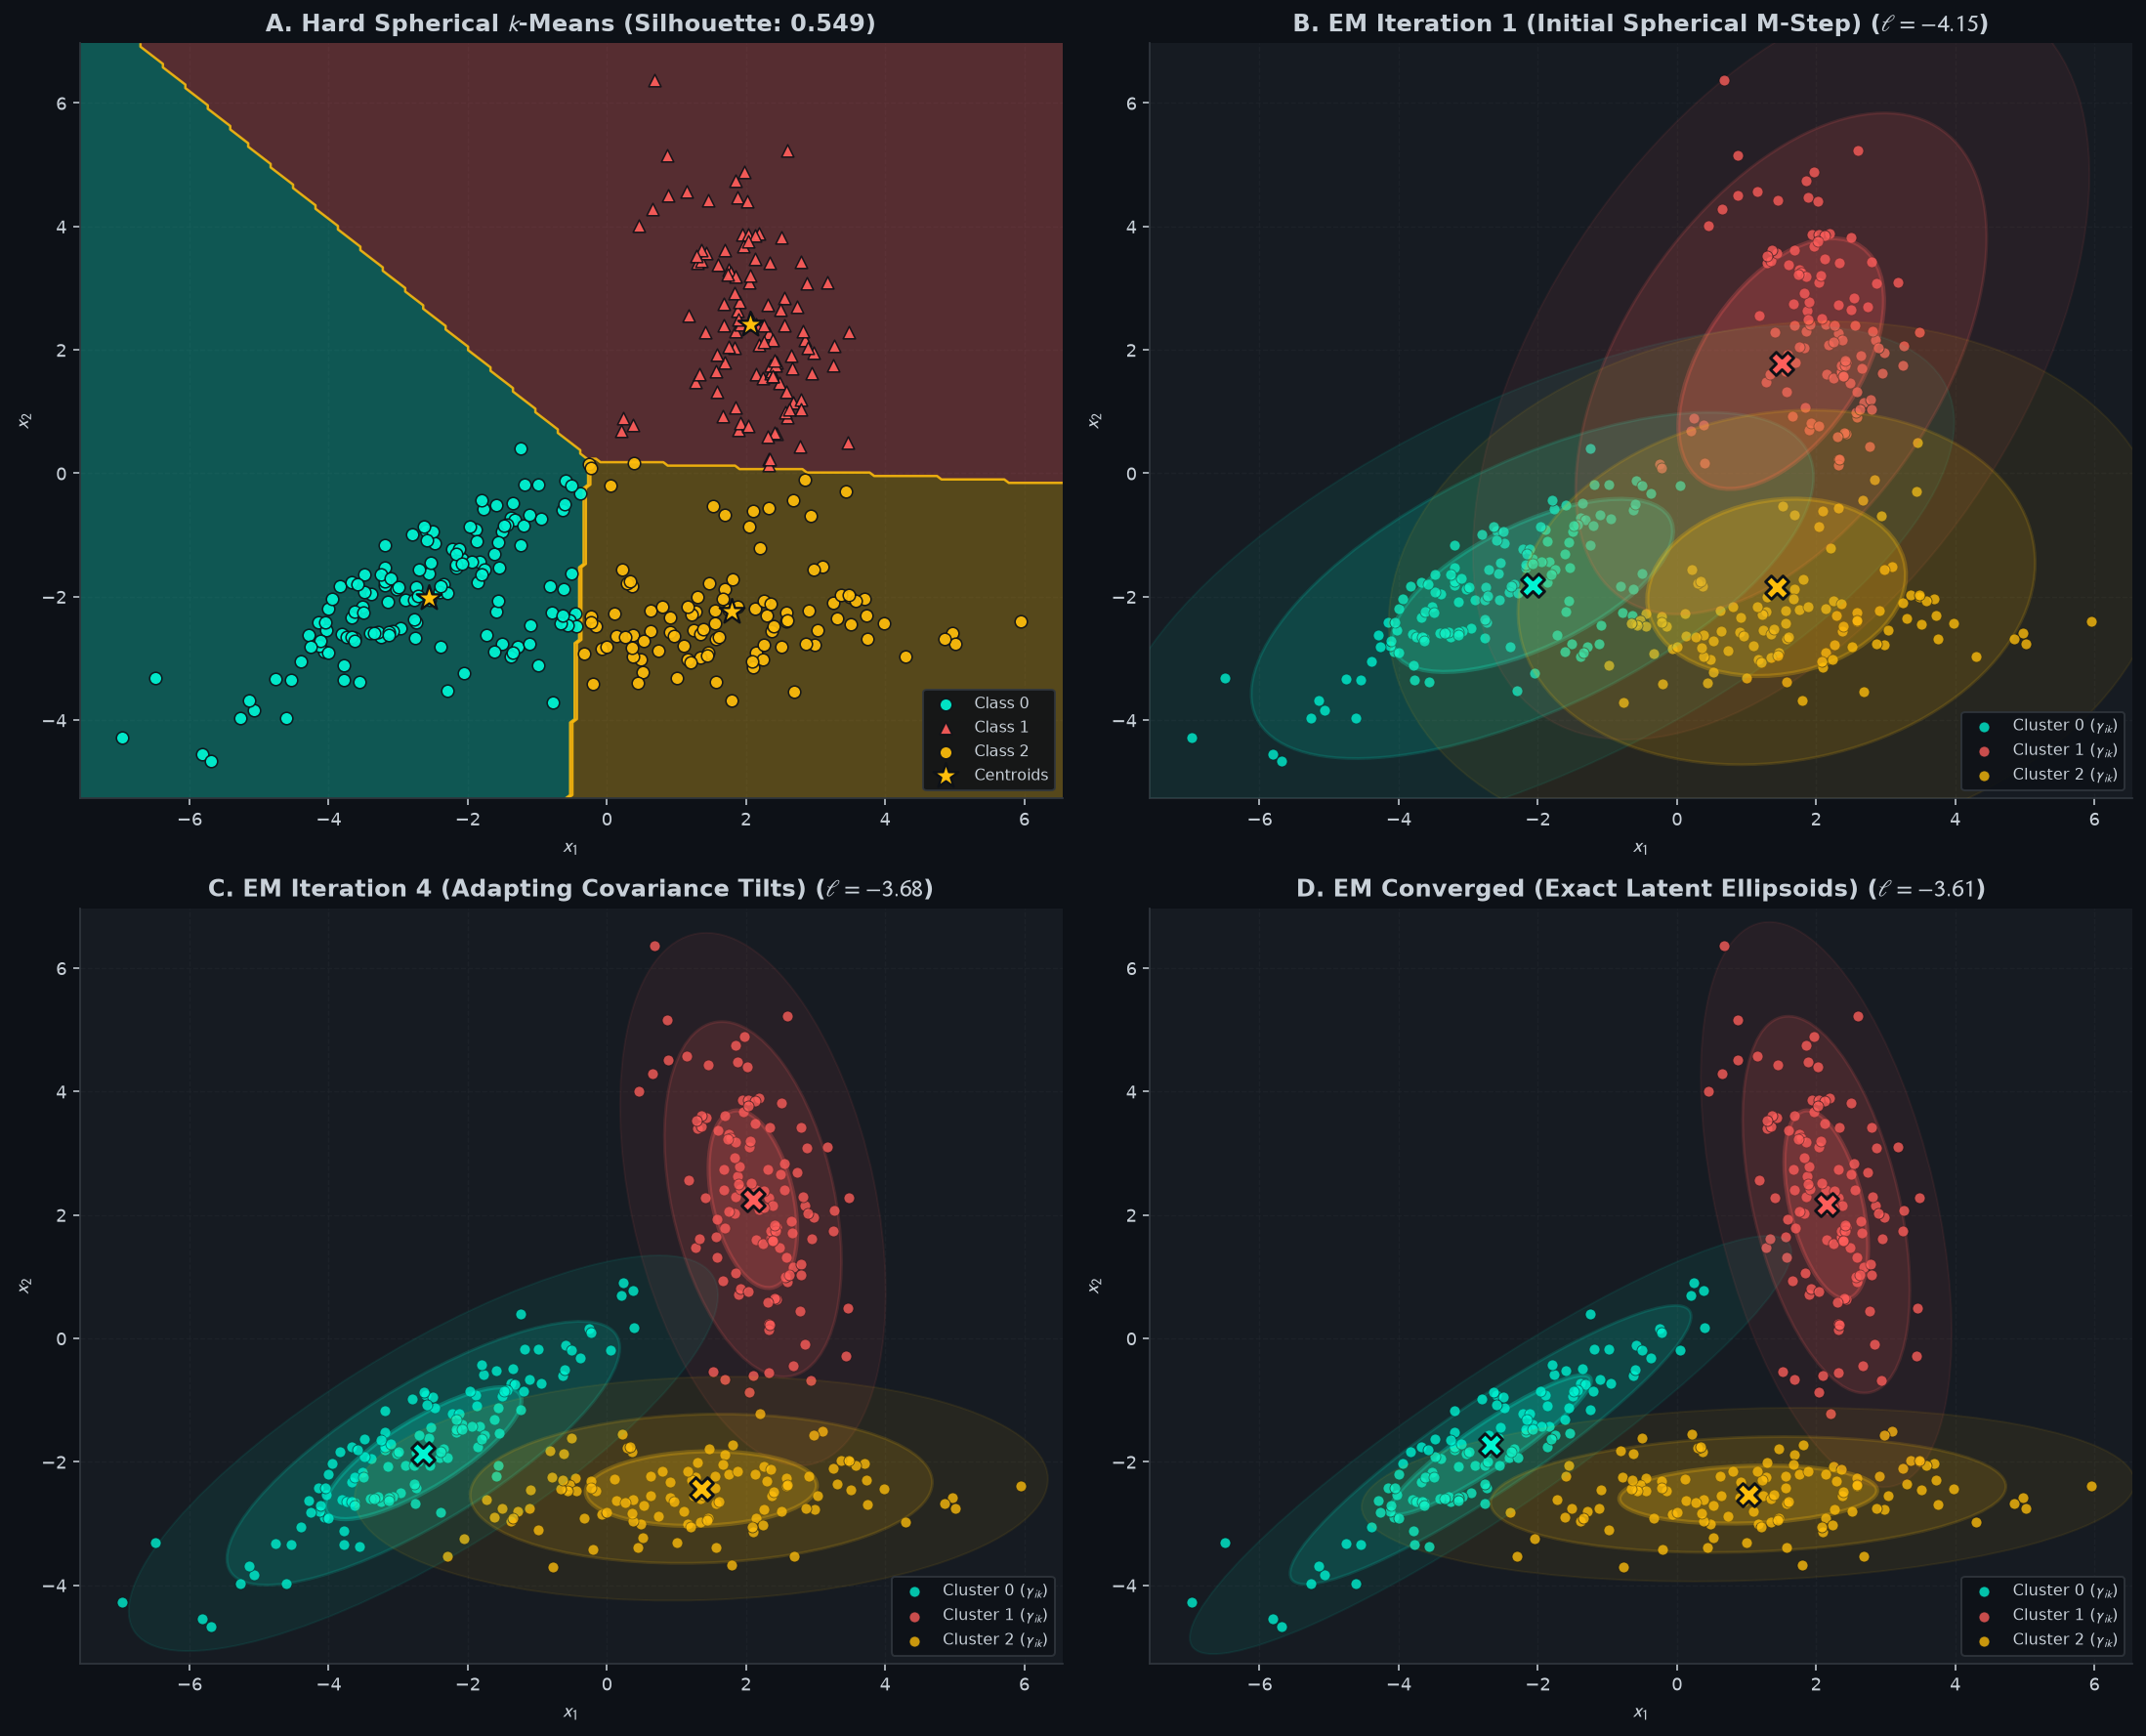

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(15.8, 12.8))
snap_iters = [(1, "B. EM Iteration 1 (Initial Spherical M-Step)"), (4, "C. EM Iteration 4 (Adapting Covariance Tilts)"), (22, "D. EM Converged (Exact Latent Ellipsoids)")]

# Panel A: Hard Spherical k-Means Voronoi Partition
ax_km = axes[0, 0]
plot_decision_boundary(
    predict_fn=lambda grid: km_model.predict(grid),
    X=X_aniso,
    y=km_model.labels_,
    ax=ax_km,
    is_probability=False,
    title=f"A. Hard Spherical $k$-Means (Silhouette: {km_sil:.3f})",
)
ax_km.scatter(
    km_model.centroids_[:, 0],
    km_model.centroids_[:, 1],
    color=AMBER,
    s=190,
    marker="*",
    edgecolors=BG_CANVAS,
    linewidths=1.2,
    zorder=10,
    label=r"Centroids",
)
ax_km.legend(loc="lower right", fontsize=8.4)

# Panels B, C, D: GMM Covariance Ellipse Evolution Across EM Steps
comp_colors = [CYAN, CORAL, AMBER]
for ax_g, (step_idx, title_g) in zip([axes[0, 1], axes[1, 0], axes[1, 1]], snap_iters):
    idx_safe = min(step_idx, len(gmm_model.means_history) - 1)
    means_s = gmm_model.means_history[idx_safe]
    covs_s = gmm_model.covs_history[idx_safe]
    ll_val = gmm_model.log_likelihood_history[min(idx_safe, len(gmm_model.log_likelihood_history) - 1)]

    # Compute soft responsibility colors for this snapshot
    log_wp = gmm_model._compute_log_weighted_prob(X_aniso, gmm_model.weights_, means_s, covs_s)
    m_lp = np.max(log_wp, axis=1, keepdims=True)
    resp_s = np.exp(log_wp - m_lp) / np.sum(np.exp(log_wp - m_lp), axis=1, keepdims=True)
    hard_lbl = np.argmax(resp_s, axis=1)

    for k_c in range(3):
        mask_k = hard_lbl == k_c
        ax_g.scatter(
            X_aniso[mask_k, 0],
            X_aniso[mask_k, 1],
            color=comp_colors[k_c],
            s=32,
            alpha=0.78,
            edgecolors=BG_CANVAS,
            linewidths=0.5,
            label=f"Cluster {k_c} ($\gamma_{{ik}}$)",
            zorder=2,
        )
        draw_covariance_ellipses(ax_g, means_s[k_c], covs_s[k_c], comp_colors[k_c])
        ax_g.scatter(
            [means_s[k_c, 0]],
            [means_s[k_c, 1]],
            color=comp_colors[k_c],
            s=150,
            marker="X",
            edgecolors=BG_CANVAS,
            linewidths=1.5,
            zorder=8,
        )

    ax_g.set_xlim(X_aniso[:, 0].min() - 0.6, X_aniso[:, 0].max() + 0.6)
    ax_g.set_ylim(X_aniso[:, 1].min() - 0.6, X_aniso[:, 1].max() + 0.6)
    ax_g.set_xlabel("$x_1$")
    ax_g.set_ylabel("$x_2$")
    ax_g.set_title(f"{title_g} ($\ell = {ll_val:.2f}$)")
    ax_g.legend(loc="lower right", fontsize=8.4)

fig.tight_layout()
assets_dir = Path("assets")
assets_dir.mkdir(parents=True, exist_ok=True)
save_fig(fig, assets_dir / "01_gmm_em_covariance_evolution.png")
plt.show()